<a href="https://colab.research.google.com/github/AjMing/Pattern-EGCI463/blob/main/Week7-8/Perceptron.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
from sklearn.linear_model import Perceptron
#

# Simple 'OR' operation

In [2]:
clf = Perceptron(verbose=1,max_iter=15,eta0=0.1,random_state=1,fit_intercept=True)


In [3]:
y=np.array([0 ,1,1,1]).T
X = np.array([   [0,0], #0

		             [0,1], #0

		             [1,0], #0

		             [1,1] ]) #1
clf.fit(X, y)


-- Epoch 1
Norm: 0.10, NNZs: 1, Bias: 0.000000, T: 4, Avg. loss: 0.025000
Total training time: 0.00 seconds.
-- Epoch 2
Norm: 0.14, NNZs: 2, Bias: 0.000000, T: 8, Avg. loss: 0.025000
Total training time: 0.00 seconds.
-- Epoch 3
Norm: 0.14, NNZs: 2, Bias: -0.100000, T: 12, Avg. loss: 0.000000
Total training time: 0.00 seconds.
-- Epoch 4
Norm: 0.22, NNZs: 2, Bias: 0.000000, T: 16, Avg. loss: 0.000000
Total training time: 0.00 seconds.
-- Epoch 5
Norm: 0.22, NNZs: 2, Bias: -0.100000, T: 20, Avg. loss: 0.000000
Total training time: 0.00 seconds.
-- Epoch 6
Norm: 0.28, NNZs: 2, Bias: 0.000000, T: 24, Avg. loss: 0.000000
Total training time: 0.00 seconds.
-- Epoch 7
Norm: 0.28, NNZs: 2, Bias: -0.100000, T: 28, Avg. loss: 0.000000
Total training time: 0.00 seconds.
-- Epoch 8
Norm: 0.28, NNZs: 2, Bias: -0.100000, T: 32, Avg. loss: 0.000000
Total training time: 0.00 seconds.
Convergence after 8 epochs took 0.00 seconds


Perceptron(eta0=0.1, max_iter=15, random_state=1, verbose=1)

In [4]:
clf.score(X, y)

1.0

In [5]:
print(clf.coef_)

[[0.2 0.2]]


In [6]:
print(clf.intercept_)
#2*x1+2*x2-2

[-0.1]


In [7]:
print(np.sum(clf.coef_*X,axis=1)+clf.intercept_) # w1x1+w2x2+y
#step function

[-0.1  0.1  0.1  0.3]


In [8]:
clf.predict(X)
#step function

array([0, 1, 1, 1])

In [9]:
clf.decision_function(X)

array([-0.1,  0.1,  0.1,  0.3])

# Weight Data

In [10]:
from google.colab import drive
from google.colab import files

drive.mount("/content/drive",force_remount=True)

Mounted at /content/drive


In [11]:
import pandas as pd

path="/content/drive/My Drive/data/"

df = pd.read_csv(path+'Weight_Height_M_W.csv')

In [12]:
df

,Height,Weight,gender
0,159.7415,57.2608,W
1,157.2365,53.1664,W
2,158.8578,49.5106,W
3,157.4017,54.1508,W
4,156.2003,52.2173,W
...,...,...,...
96,172.1863,63.6287,M
97,168.9630,55.1719,M
98,172.8701,53.6238,M
99,171.1873,62.8852,M


In [13]:
df.loc[df['gender']=='M','Class']=0
df.loc[df['gender']=='W','Class']=1

In [14]:
df

,Height,Weight,gender,Class
0,159.7415,57.2608,W,1.0
1,157.2365,53.1664,W,1.0
2,158.8578,49.5106,W,1.0
3,157.4017,54.1508,W,1.0
4,156.2003,52.2173,W,1.0
...,...,...,...,...
96,172.1863,63.6287,M,0.0
97,168.9630,55.1719,M,0.0
98,172.8701,53.6238,M,0.0
99,171.1873,62.8852,M,0.0


In [15]:
x_data=df.iloc[:,0:2]
y_data=df.iloc[:,-1]

In [16]:
print(x_data)
print(y_data)

       Height   Weight
0    159.7415  57.2608
1    157.2365  53.1664
2    158.8578  49.5106
3    157.4017  54.1508
4    156.2003  52.2173
..        ...      ...
96   172.1863  63.6287
97   168.9630  55.1719
98   172.8701  53.6238
99   171.1873  62.8852
100  168.6423  75.0807

[101 rows x 2 columns]
0      1.0
1      1.0
2      1.0
3      1.0
4      1.0
      ... 
96     0.0
97     0.0
98     0.0
99     0.0
100    0.0
Name: Class, Length: 101, dtype: float64


In [32]:
np.mean(x_data,axis=0)

,0
Height,163.500918
Weight,57.533844


In [33]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(x_data, y_data, test_size=0.2, random_state=42, stratify=y_data)

print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)

Training set size: (80, 2)
Testing set size: (21, 2)


In [34]:
from sklearn.linear_model import Perceptron
clf = Perceptron(verbose=1,random_state=2,eta0=100)
clf.fit(X_train,y_train)

-- Epoch 1
Norm: 9567.11, NNZs: 2, Bias: 200.000000, T: 80, Avg. loss: 784438.801858
Total training time: 0.00 seconds.
-- Epoch 2
Norm: 532.76, NNZs: 2, Bias: 300.000000, T: 160, Avg. loss: 846071.916527
Total training time: 0.00 seconds.
-- Epoch 3
Norm: 12767.31, NNZs: 2, Bias: 500.000000, T: 240, Avg. loss: 699025.051264
Total training time: 0.00 seconds.
-- Epoch 4
Norm: 12299.37, NNZs: 2, Bias: 500.000000, T: 320, Avg. loss: 825095.570127
Total training time: 0.00 seconds.
-- Epoch 5
Norm: 13829.23, NNZs: 2, Bias: 600.000000, T: 400, Avg. loss: 650413.849819
Total training time: 0.00 seconds.
-- Epoch 6
Norm: 15236.58, NNZs: 2, Bias: 900.000000, T: 480, Avg. loss: 720038.154943
Total training time: 0.00 seconds.
-- Epoch 7
Norm: 12980.97, NNZs: 2, Bias: 900.000000, T: 560, Avg. loss: 795745.074141
Total training time: 0.00 seconds.
-- Epoch 8
Norm: 11454.80, NNZs: 2, Bias: 1100.000000, T: 640, Avg. loss: 787467.186701
Total training time: 0.00 seconds.
-- Epoch 9
Norm: 16741.32, 

Perceptron(eta0=100, random_state=2, verbose=1)

In [35]:
print(clf.coef_ )
print(clf.intercept_)

[[  9367.89 -14806.84]]
[1400.]


In [36]:
print(clf.score(x_data,y_data))

0.48514851485148514


In [37]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
class_names = ['M', 'F']
cm = confusion_matrix(y_data, clf.predict(x_data))
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=class_names)

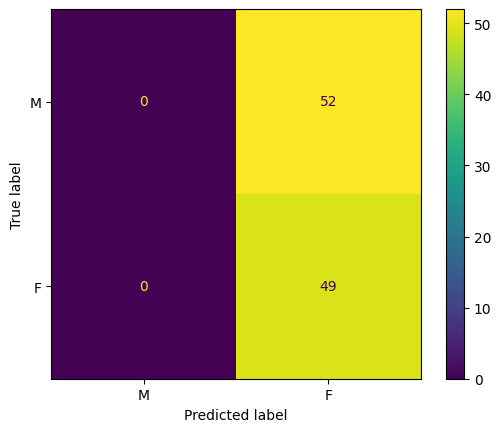

In [38]:
disp.plot()

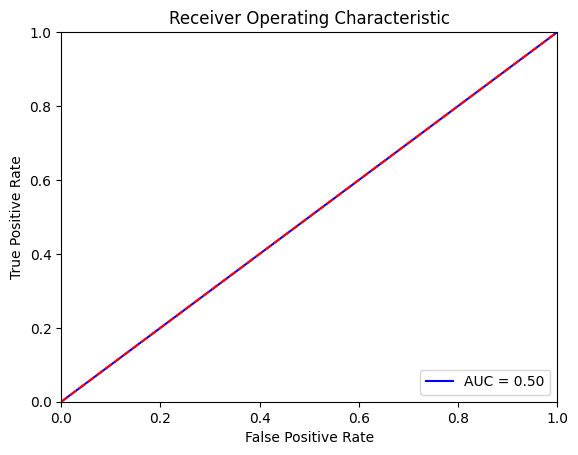

In [39]:
output = clf.predict(x_data)
from sklearn import metrics
fpr, tpr, threshold = metrics.roc_curve(y_data, output)
roc_auc = metrics.auc(fpr, tpr)

# method I: plt
import matplotlib.pyplot as plt
plt.title('Receiver Operating Characteristic')
plt.plot(fpr, tpr, 'b', label = 'AUC = %0.2f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'r--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()

In [40]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(clf, X_train,y_train, cv=5)
print(scores)

-- Epoch 1
Norm: 14283.53, NNZs: 2, Bias: 0.000000, T: 64, Avg. loss: 638454.890138
Total training time: 0.00 seconds.
-- Epoch 2
Norm: 2837.22, NNZs: 2, Bias: 200.000000, T: 128, Avg. loss: 811259.113537
Total training time: 0.00 seconds.
-- Epoch 3
Norm: 18762.92, NNZs: 2, Bias: 200.000000, T: 192, Avg. loss: 723630.837892
Total training time: 0.00 seconds.
-- Epoch 4
Norm: 4763.69, NNZs: 2, Bias: 400.000000, T: 256, Avg. loss: 684021.045220
Total training time: 0.00 seconds.
-- Epoch 5
Norm: 5344.70, NNZs: 2, Bias: 500.000000, T: 320, Avg. loss: 631257.077033
Total training time: 0.00 seconds.
-- Epoch 6
Norm: 16667.90, NNZs: 2, Bias: 700.000000, T: 384, Avg. loss: 915643.237251
Total training time: 0.00 seconds.
-- Epoch 7
Norm: 18247.96, NNZs: 2, Bias: 700.000000, T: 448, Avg. loss: 985666.341170
Total training time: 0.00 seconds.
-- Epoch 8
Norm: 22213.95, NNZs: 2, Bias: 800.000000, T: 512, Avg. loss: 759104.191932
Total training time: 0.00 seconds.
-- Epoch 9
Norm: 14911.89, NNZ

# Data Standardization

In [82]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
x_std = scaler.fit_transform(X_train)
print(x_std)
x_test_std=scaler.transform(X_test)

[[0.53851783 0.77070796]
 [0.21799786 0.30382681]
 [0.09383147 0.27878573]
 [0.20129353 0.37609647]
 [0.30831649 0.46242588]
 [0.81429473 0.53860119]
 [0.68693111 0.15230341]
 [0.3378235  0.14891408]
 [0.78161792 0.87687371]
 [0.26095249 0.67042982]
 [0.7089413  0.69119051]
 [0.48685426 0.04502731]
 [0.07919918 0.45128078]
 [0.37475872 0.63539006]
 [0.37796054 0.38867391]
 [0.7692269  0.3666502 ]
 [0.4050113  0.36167307]
 [0.63468206 1.        ]
 [0.81632102 0.7929121 ]
 [0.14634124 0.32242511]
 [0.31901512 0.26706602]
 [0.83095789 0.3705253 ]
 [0.90882146 0.36146766]
 [0.69815118 0.85306233]
 [0.56874754 0.58713164]
 [0.71378976 0.9553502 ]
 [0.27691125 0.34250294]
 [0.87009779 0.60007828]
 [0.         0.43572206]
 [0.24645742 0.57998101]
 [0.17980021 0.27078291]
 [0.14654707 0.31180187]
 [0.93552002 0.37010615]
 [0.26103483 0.42650341]
 [0.15781289 0.18477271]
 [0.8061484  0.57701084]
 [0.62443625 0.47543359]
 [0.10636429 0.1344768 ]
 [0.3006367  0.4501982 ]
 [0.78025944 0.54223202]


In [83]:
from sklearn.linear_model import Perceptron
clf_std = Perceptron()
from sklearn.model_selection import cross_val_score
scores = cross_val_score(clf_std, x_std,y_train, cv=5)

In [84]:
scores
print(scores)

[1.     0.9375 1.     1.     0.9375]


In [99]:
clf_std =Perceptron(verbose=1,random_state=10)
clf_std.fit(x_std,y_train)

-- Epoch 1
Norm: 3.07, NNZs: 2, Bias: 1.000000, T: 80, Avg. loss: 0.115853
Total training time: 0.00 seconds.
-- Epoch 2
Norm: 3.79, NNZs: 2, Bias: 2.000000, T: 160, Avg. loss: 0.058245
Total training time: 0.00 seconds.
-- Epoch 3
Norm: 4.30, NNZs: 2, Bias: 2.000000, T: 240, Avg. loss: 0.022240
Total training time: 0.00 seconds.
-- Epoch 4
Norm: 4.96, NNZs: 2, Bias: 2.000000, T: 320, Avg. loss: 0.032827
Total training time: 0.00 seconds.
-- Epoch 5
Norm: 5.23, NNZs: 2, Bias: 2.000000, T: 400, Avg. loss: 0.016060
Total training time: 0.00 seconds.
-- Epoch 6
Norm: 5.27, NNZs: 2, Bias: 2.000000, T: 480, Avg. loss: 0.012336
Total training time: 0.00 seconds.
-- Epoch 7
Norm: 5.41, NNZs: 2, Bias: 2.000000, T: 560, Avg. loss: 0.005730
Total training time: 0.00 seconds.
-- Epoch 8
Norm: 5.45, NNZs: 2, Bias: 2.000000, T: 640, Avg. loss: 0.011680
Total training time: 0.00 seconds.
-- Epoch 9
Norm: 5.63, NNZs: 2, Bias: 2.000000, T: 720, Avg. loss: 0.006987
Total training time: 0.00 seconds.
--

Perceptron(random_state=10, verbose=1)

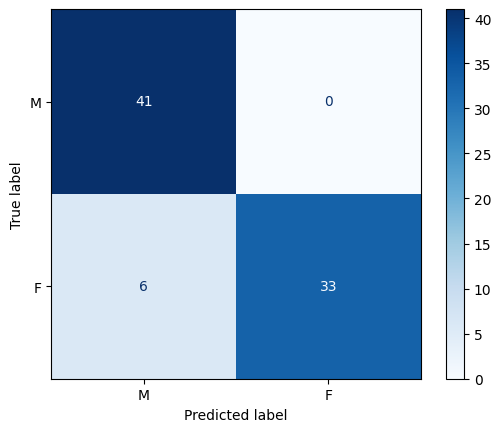

In [100]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
class_names = ['M', 'F']
disp = ConfusionMatrixDisplay.from_estimator(clf_std, x_std, y_train, display_labels=class_names, cmap=plt.cm.Blues)

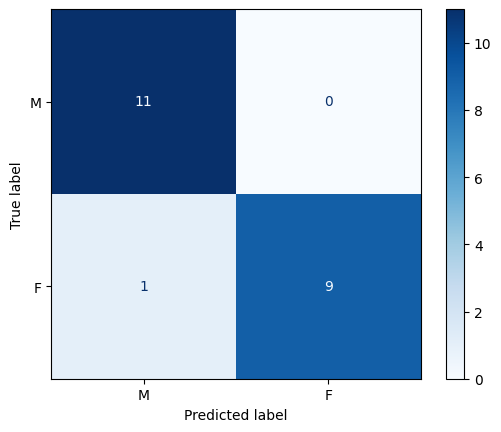

In [101]:
disp = ConfusionMatrixDisplay.from_estimator(clf_std, x_test_std, y_test, display_labels=class_names, cmap=plt.cm.Blues)

# A few more parameter.

In [105]:
clf_std2 =Perceptron(verbose=1,fit_intercept=False,tol=0.0001, random_state=0,eta0=1)
clf_std2.fit(x_std,y_train)

-- Epoch 1
Norm: 1.77, NNZs: 2, Bias: 0.000000, T: 80, Avg. loss: 0.067805
Total training time: 0.00 seconds.
-- Epoch 2
Norm: 1.49, NNZs: 2, Bias: 0.000000, T: 160, Avg. loss: 0.053443
Total training time: 0.00 seconds.
-- Epoch 3
Norm: 1.79, NNZs: 2, Bias: 0.000000, T: 240, Avg. loss: 0.054653
Total training time: 0.00 seconds.
-- Epoch 4
Norm: 1.83, NNZs: 2, Bias: 0.000000, T: 320, Avg. loss: 0.062929
Total training time: 0.00 seconds.
-- Epoch 5
Norm: 1.45, NNZs: 2, Bias: 0.000000, T: 400, Avg. loss: 0.078805
Total training time: 0.00 seconds.
-- Epoch 6
Norm: 2.10, NNZs: 2, Bias: 0.000000, T: 480, Avg. loss: 0.067416
Total training time: 0.00 seconds.
-- Epoch 7
Norm: 1.86, NNZs: 2, Bias: 0.000000, T: 560, Avg. loss: 0.069849
Total training time: 0.00 seconds.
Convergence after 7 epochs took 0.00 seconds


Perceptron(eta0=1, fit_intercept=False, tol=0.0001, verbose=1)

In [106]:
print(clf_std2.coef_)
print(clf_std2.intercept_)
print(clf_std2.score(x_std,y_train))

[[-1.57348165  0.9979875 ]]
[0.]
0.75


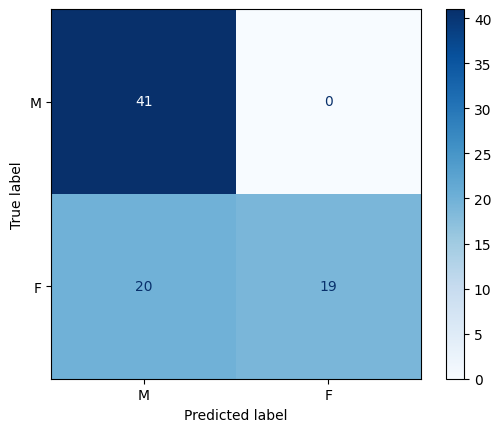

In [107]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
class_names = ['M', 'F']
disp = ConfusionMatrixDisplay.from_estimator(clf_std2, x_std, y_train, display_labels=class_names, cmap=plt.cm.Blues)

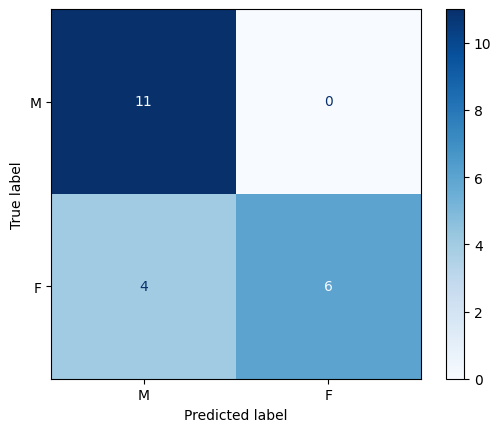

In [108]:
disp = ConfusionMatrixDisplay.from_estimator(clf_std2, x_test_std, y_test, display_labels=class_names, cmap=plt.cm.Blues)

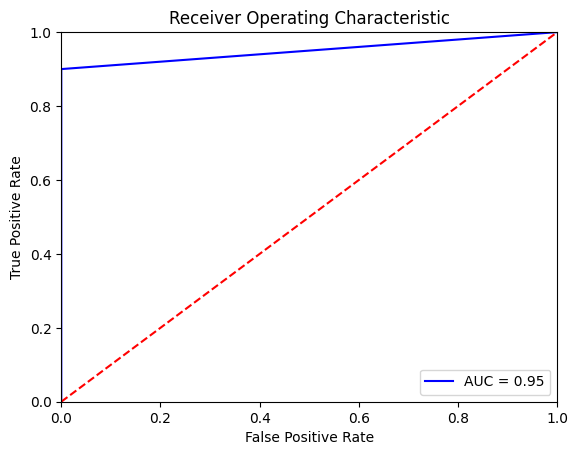

In [109]:
import sklearn.metrics as metrics
# calculate the fpr and tpr for all thresholds of the classification

probs = clf_std.predict(x_test_std)

fpr, tpr, threshold = metrics.roc_curve(y_test, probs)
roc_auc = metrics.auc(fpr, tpr)

# method I: plt
import matplotlib.pyplot as plt
plt.title('Receiver Operating Characteristic')
plt.plot(fpr, tpr, 'b', label = 'AUC = %0.2f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'r--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()

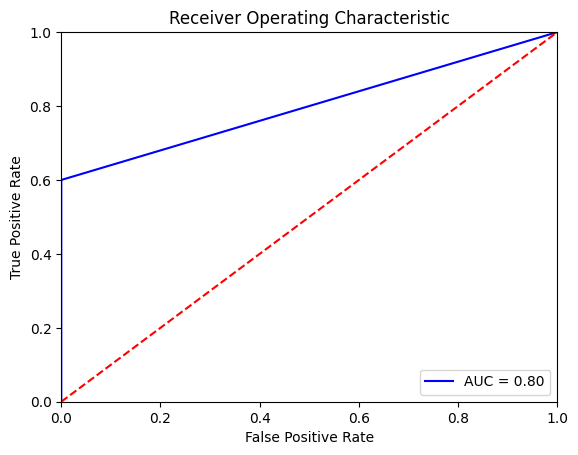

In [110]:
import sklearn.metrics as metrics
# calculate the fpr and tpr for all thresholds of the classification

probs = clf_std2.predict(x_test_std)

fpr, tpr, threshold = metrics.roc_curve(y_test, probs)
roc_auc = metrics.auc(fpr, tpr)

# method I: plt
import matplotlib.pyplot as plt
plt.title('Receiver Operating Characteristic')
plt.plot(fpr, tpr, 'b', label = 'AUC = %0.2f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'r--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()